# Tracking aspherical particles from 2D brightfield images

In [1]:
# To do
# Check consistency between time the package and time the variable used somewhere.

# Importations

In [1]:
# import sys
# sys.path.append("/home/nfares/postdoc/experiments/tracking/utilities/")

In [2]:
# os.environ["OMP_NUM_THREADS"] = "30"
# os.environ["MKL_NUM_THREADS"] = "30"

In [3]:
import numpy as np
import math
import pandas as pd

# import pims
# import trackpy as tp

import cv2

from skimage.measure import label, regionprops, find_contours

from tqdm import tqdm
import os
import time 

from scipy.optimize import curve_fit

In [4]:
# import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rc

# change the following to %matplotlib notebook for interactive plotting
%matplotlib inline

# Optionally, tweak styles.
rc('lines', linewidth=1.5, markeredgecolor='k', markeredgewidth=0.5)
rc('xtick', direction='in', labelsize=10)
rc('ytick', direction='in', labelsize=10)
rc('font', family='serif', size=10)
rc('text', usetex=True)
rc('image', cmap='gray')
rc('figure', dpi=200)
rc('savefig', dpi=200)

In [5]:
# from ring_tracking import locate_ring
# from inner_part_tracking import locate_inner_part
from multi_particle_tracking import locate_particles, particles_to_rows, link_trajectories

# Auxiliary functions

# Inputs

In [6]:
# 
# Global variable to not save twice or erase...
#

already_saved = False

#
#
#

In [7]:
# Where to find the data
path2vid = '/home/nfares/postdoc/experiments/data/Rattler/20261006_rattler_diffusing_in_dextran/chain/fluto_fps_10Hz_calib_44nm_light_440nm_intensity_50percent.tif'

# Frame rate
fps = 10

# Pixel size (in m)
px = 44e-9

# Name to save

index = path2vid[::-1].find('/')
path2save = path2vid[:-index:] + 'trajectories_' + path2vid[-index:path2vid.find('.tif'):] + '_fps_{0}Hz_px_{1}nm'.format(int(fps), int(px*1e9))
print(path2save)

# index = path2vid.find('iro')
# path2save = path2vid[:index:] + 'trajectories_' + path2vid[index:-1:] + '_fps_{0}Hz_px_{1}nm'.format(int(fps), int(px*1e9))
# print(path2save)

/home/nfares/postdoc/experiments/data/Rattler/20261006_rattler_diffusing_in_dextran/chain/trajectories_fluto_fps_10Hz_calib_44nm_light_440nm_intensity_50percent_fps_10Hz_px_44nm


In [8]:
int(px * 1e9)

44

# Get the frames 

In [170]:
# Functions to open tiff files

import re
from pathlib import Path
import tifffile

# ----------------------------------------------------------------------
# If single multi-page TIFF
# ----------------------------------------------------------------------

def load_multipage_tiff(path):
    """
    Load a multi-page TIFF into a 3D array (n_frames, height, width).
    Works for a single-page tiff too (returns n_frames=1).axes[1].imshow(binary, cmap='gray');  axes[1].set_title('Binary')

    """
    stack = tifffile.imread(path)  # shape (N, H, W) if multi-page, (H, W) if single
    if stack.ndim == 2:
        stack = stack[np.newaxis, ...]
    return stack  # index frames as stack[i]

# ----------------------------------------------------------------------
# If folder of individual TIFF files (one frame per file)
# ----------------------------------------------------------------------
def _natural_key(path):
    """Sort 'frame2.tif' before 'frame10.tif' (plain sort would do the opposite)."""
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", path.stem)]
 
 
def load_tiff_stack_folder(folder, pattern="*.tif*"):
    """
    Load every TIFF file in a folder, sorted in natural frame order, into a
    list of 2D arrays. Use a list (not a forced np.stack) in case frame
    sizes ever differ; stack yourself with np.stack(frames) if they're all
    the same shape and you want a single 3D array.
    """
    paths = sorted(Path(folder).glob(pattern), key=_natural_key)
    if not paths:
        raise FileNotFoundError(f"No TIFF files found in {folder} matching {pattern}")
    frames = [tifffile.imread(p) for p in paths]
    return frames, paths  # paths returned too, useful for logging/debugging

# ----------------------------------------------------------------------
# Wrapping function to choose between the two above
# ----------------------------------------------------------------------

def open_tiff_file(path):
    if path[-1] == 'f':
        return load_multipage_tiff(path)
    if path[-1] == '/':
        return load_tiff_stack_folder(path)[0]
    else:
        raise FileNotFoundError

In [171]:


# stack = load_multipage_tiff(path2vid)
# stack, _ = load_tiff_stack_folder(path2vid)
stack = open_tiff_file(path2vid)



In [172]:
print(len(stack))

601


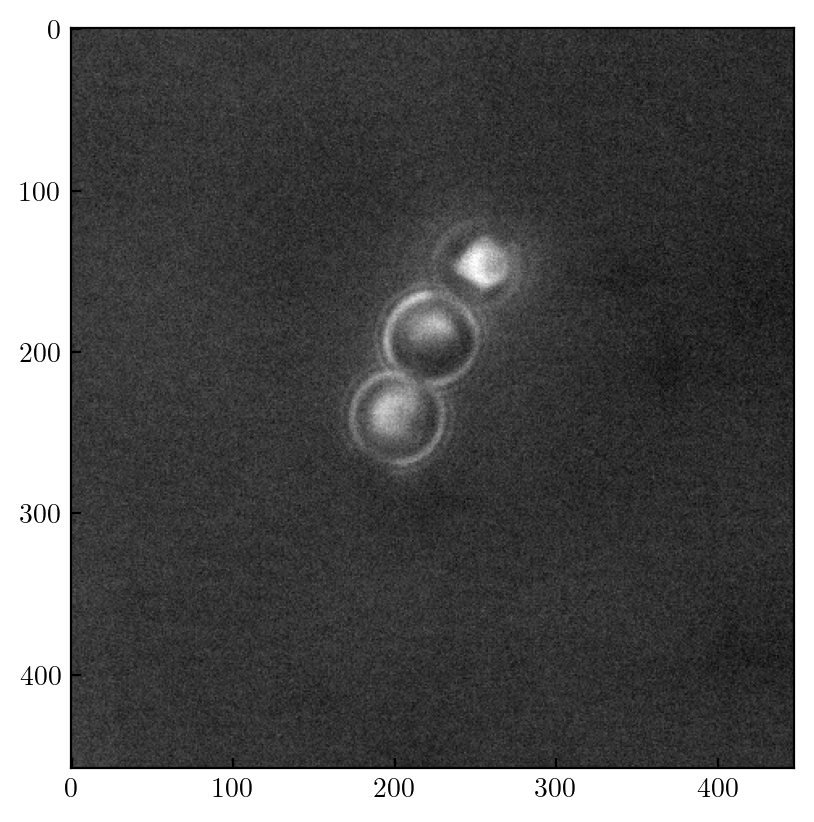

In [160]:
i = 240
plt.imshow(stack[i])

In [15]:
# for i in range(0, 10, 1):
#     plt.imsave('im_' +str(i)+'.png', stack[i])

In [161]:
# plt.imsave('im_' +str(i)+'.png', stack[i])

# Test on one image

In [162]:
RING_RADIUS = 29   # px, about the LARGEST ring in the movie
RANGE_LOWER_PX = 6
RANGE_UPPER_PX = 6
MIN_SNR = 2
SMOOTHING_SIGMA = 1.5

In [163]:
i = 240

img = stack[i]

xsize, ysize = img.shape[::-1]

particles = locate_particles(
    img,
    RING_RADIUS,  # ring_radius: the scale for detection, crops and checks
    ring_kwargs=dict(
        min_snr=MIN_SNR,
        smoothing_sigma=SMOOTHING_SIGMA,
        range_lower_px=RANGE_LOWER_PX,
        range_upper_px=RANGE_UPPER_PX,
        # fixed_params={"a": Rr, "sigma": Sr},
    ),
    isolate=True, 
)

rows = particles_to_rows(particles, i, fps, ysize)

rows = pd.DataFrame(rows)

rows

,frame,time,xs,ys,as,sigmas,Is_max,Is,snr,xc,yc,Ac,Ic,edge_effect
0,240,24.0,222.072604,264.888202,26.623618,2.308038,14565.724708,1.409652e+07,4.946140,221.567019,273.720264,641,1.265625e+07,False
1,240,24.0,201.638470,217.526296,27.610809,1.776214,11344.377809,8.762438e+06,2.003672,198.981519,221.730435,1047,2.255034e+07,False


In [164]:
def plot_frame_tracking(img, results, frame, px=1.0, ysize=None, ax=None,
                        plot_trajectory=True, trail_length=None, show_inner=True,
                        show_ids=True, margin=None, cmap="gray"):
    """
    Draw `img` with the ring fits, centers, inner-part COMs and particle
    IDs of `frame`, plus (optionally) each particle's trajectory so far.

    img      : 2D array, the image of that frame (e.g. stack[frame]).
    results  : DataFrame with columns frame, xs, ys, as, xc, yc and
               (after linking) particle.
    frame    : frame number, as in results["frame"].
    px       : size of one pixel in the DataFrame's units. 1.0 if results
               are still in pixels; your `px` if you already converted
               xs, ys, as, xc, yc to SI units.
    ysize    : image height in px used for the y flip (ys = ysize - y).
               Default img.shape[0], i.e. the same as in the loop.
    ax       : matplotlib Axes to draw on; a new figure if None.
    plot_trajectory : if True (default), also draw each particle's
               ring-center path up to this frame. False = only the
               particles of this frame.
    trail_length : with plot_trajectory, only the last N frames of the
               path (None = all).
    show_inner : draw the inner-part center of mass.
    show_ids : write the trackpy particle ID next to each particle.
    margin     : optional margin in px: crop the view to the particles in
               this frame plus this margin. None = whole image.

    Returns the Axes.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))
    if ysize is None:
        ysize = img.shape[0]

    def to_img(x, y):
        # DataFrame -> image pixel coordinates (undo unit conversion and y flip)
        return np.asarray(x) / px, ysize - np.asarray(y) / px

    ax.imshow(img, cmap=cmap)
    cur = results[results["frame"] == frame]
    has_id = "particle" in results.columns
    # colors = plt.get_cmap("tab10")
    colors = plt.get_cmap("RdYlBu_r")
    theta = np.linspace(0, 2 * np.pi, 200)

    for _, row in cur.iterrows():
        pid = int(row["particle"]) if has_id else None
        c = colors(pid % 10) if has_id else "lightskyblue"
        if np.isnan(row["xs"]):
            continue
        cx, cy = to_img(row["xs"], row["ys"])
        a = row["as"] / px

        # ring fit and its center
        ax.plot(cx + a * np.cos(theta), cy + a * np.sin(theta), "-", c=c, lw=1.5)
        ax.plot(cx, cy, "+", mec=c, ms=12, mew=2)

        # inner-part center of mass
        if show_inner and not np.isnan(row.get("xc", np.nan)):
            ix, iy = to_img(row["xc"], row["yc"])
            ax.plot(ix, iy, "x", mec="tab:red", ms=8, mew=1.8)

        if show_ids and has_id:
            ax.text(cx + 0.75 * a, cy - 0.75 * a, str(pid), color=c, fontsize=11,
                    fontweight="bold")

        # path of this particle up to the current frame
        if plot_trajectory and has_id:
            path = results[(results["particle"] == pid) & (results["frame"] <= frame)]
            if trail_length is not None:
                path = path[path["frame"] > frame - trail_length]
            path = path.sort_values("frame")
            tx, ty = to_img(path["xs"], path["ys"])
            ax.plot(tx, ty, "-", c=c, lw=1, alpha=0.8)

    if margin is not None and len(cur):
        xs, ys = to_img(cur["xs"], cur["ys"])
        r = (cur["as"] / px).max()
        ax.set_xlim(np.nanmin(xs) - r - margin, np.nanmax(xs) + r + margin)
        ax.set_ylim(np.nanmax(ys) + r + margin, np.nanmin(ys) - r - margin)

    # ax.set_title(f"Frame {frame}")
    ax.axis("off")
    return ax

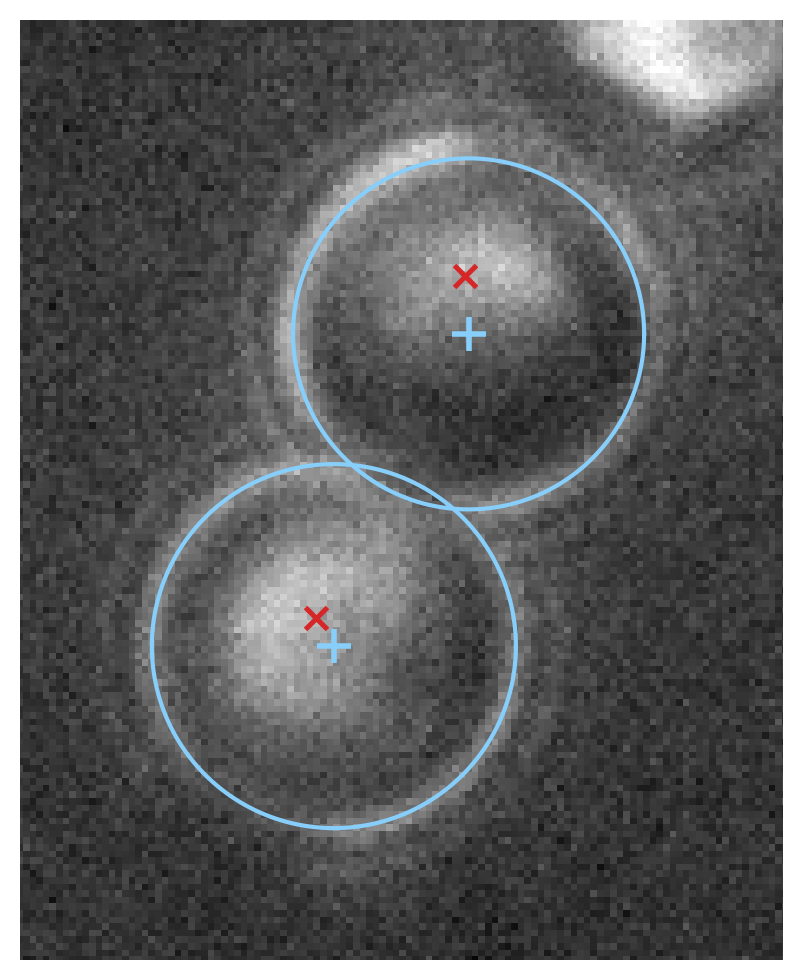

In [165]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
_ = plot_frame_tracking(img, rows, i, px=1, ysize=ysize, margin=20, plot_trajectory=False, ax=ax)
plt.tight_layout()
plt.show()

In [159]:
# fig.savefig('test.pdf', transparent=True)

In [130]:
del particles, rows

# Tracking

In [132]:
# Parameters

# Number of particles to be tracked
N_particles = 3 

# Images to track
start = 0
stop = 601
step = 30

# Number of images
Nim = math.ceil((stop - start) / step)
print(f"{Nim} images will be tracked.")

# Nim = 100 #len(stack)

# Dimensions of the images
xsize, ysize = stack[0].shape[::-1]

21 images will be tracked.


In [133]:
results = []
frames_with_missing_p = []

for i in tqdm(range(start, stop, step)):
    img = stack[i]
    particles = locate_particles(
        img,
        RING_RADIUS,  # ring_radius: the scale for detection, crops and checks
        ring_kwargs=dict(
            min_snr=MIN_SNR,
            smoothing_sigma=SMOOTHING_SIGMA,
            range_lower_px=RANGE_LOWER_PX,
            range_upper_px=RANGE_UPPER_PX,
            # fixed_params={"a": Rr, "sigma": Sr},
        ),
    )
    rows = particles_to_rows(particles, i, fps, ysize)

    # If we miss particles, we do not keep the positions of the chain
    if len(particles) != N_particles:
        frames_with_missing_p.append(i)
        cols = rows.columns.difference(['frame', 'time'])
        rows[cols] = np.nan
        
    results += rows
    
    # Plot & save
    rows = pd.DataFrame(rows)
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    _ = plot_frame_tracking(img, rows, i, px=1, ysize=ysize, margin=20, plot_trajectory=False, ax=ax)
    plt.tight_layout()
    fig.savefig(f'./temp/im_{i}.png')
    plt.close()

results = pd.DataFrame(results)

print('Frames in which less particles were found:')
print(frames_with_missing_p)

del particles, rows, img

100%|███████████████████████████████████████████| 21/21 [00:47<00:00,  2.28s/it]

Frames in which less particles were found:
[240, 360, 480]


In [134]:
# Linking of trajectories
results = link_trajectories(results, search_range=10, memory=3)   # in px, before conversion

# Conversion to SI
for col in ("xs", "ys", "as", "sigmas", "xc", "yc"):
    results[col] = results[col] * px
results["Ac"] = results["Ac"] * px ** 2

Frame 600: 3 trajectories present.


In [135]:
results.head(10)

,frame,time,xs,ys,as,sigmas,Is_max,Is,snr,xc,yc,Ac,Ic,edge_effect,particle
0,0,0.0,0.000010,0.000011,0.000001,8.506623e-08,13973.668920,1.154957e+07,4.669027,0.000010,0.000012,1.275824e-12,12687557.0,False,0
1,0,0.0,0.000008,0.000010,0.000001,8.592535e-08,11458.981223,9.492079e+06,3.612575,0.000007,0.000010,2.205104e-12,25085022.0,False,1
2,0,0.0,0.000012,0.000013,0.000001,8.279907e-08,11355.878285,9.463297e+06,3.466796,0.000012,0.000013,2.150896e-12,25330452.0,False,2
3,30,3.0,0.000008,0.000010,0.000001,7.782458e-08,15047.139408,1.157363e+07,4.809879,0.000008,0.000010,1.887600e-12,14786781.0,False,3
4,30,3.0,0.000010,0.000011,0.000001,8.966871e-08,14549.555225,1.268731e+07,4.801556,0.000010,0.000012,1.299056e-12,13205757.0,False,4
5,30,3.0,0.000012,0.000013,0.000001,7.939777e-08,15850.024666,1.281029e+07,4.526898,0.000012,0.000013,1.835328e-12,20294648.0,False,5
6,60,6.0,0.000010,0.000011,0.000001,8.650678e-08,16529.340873,1.401960e+07,5.536462,0.000010,0.000012,1.206128e-12,12449952.0,False,6
7,60,6.0,0.000012,0.000013,0.000001,8.120345e-08,15365.438147,1.271311e+07,4.681075,0.000012,0.000013,2.129600e-12,24477229.0,False,7
8,60,6.0,0.000009,0.000009,0.000001,1.519742e-07,13573.352621,2.054014e+07,4.037040,0.000008,0.000009,1.037696e-12,7654404.0,False,8
9,90,9.0,0.000010,0.000011,0.000001,8.893380e-08,15574.194430,1.348903e+07,5.271890,0.000010,0.000012,1.246784e-12,12470410.0,False,9


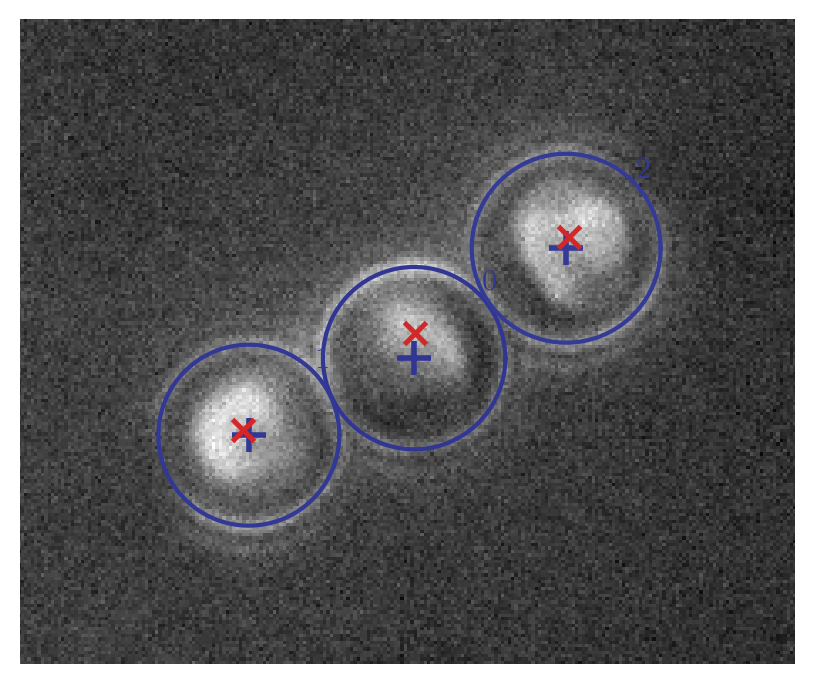

In [136]:
# from plot_tracking import plot_frame_tracking
i = 0
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
_ = plot_frame_tracking(stack[i], results, i, px=px, ysize=ysize, margin=40, plot_trajectory=False, ax=ax)
plt.show()

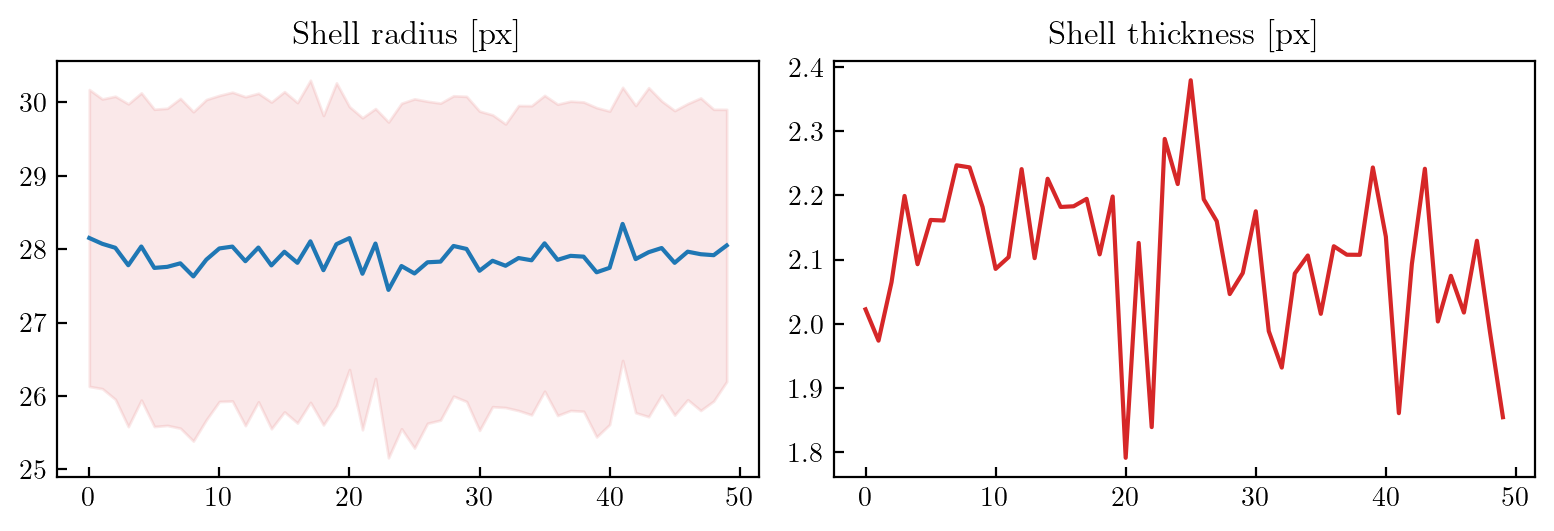

In [59]:
fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(20/2.54, 7/2.54))

cond = Router > 0

ax1.plot(np.arange(len(Router[cond])), Router[cond], ls='-', c='tab:blue')
ax1.fill_between(np.arange(len(Router[cond])), Router[cond] - Souter[cond], Router[cond]+Souter[cond], color='tab:red', alpha=0.1)

ax2.plot(Souter[cond], ls='-', c='tab:red')

ax1.set_title(r'Shell radius [px]')
ax2.set_title(r'Shell thickness [px]')

plt.tight_layout()
plt.show()

In [60]:
# fig.savefig('radii_without_uint8_conversion.pdf')

In [ ]:
if not(already_saved):
    results.to_csv(path2save + '.csv', index=False)
    already_save = True

# Quick analysis

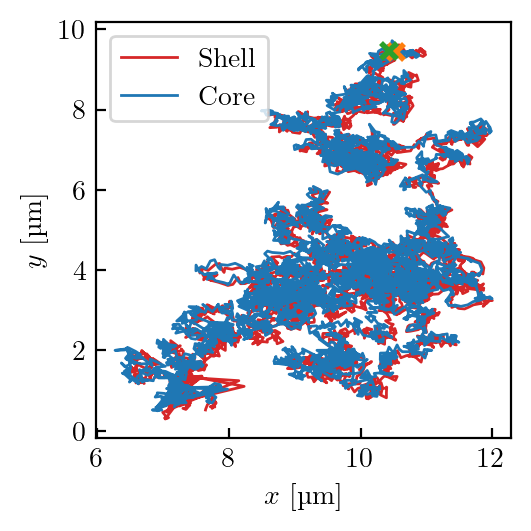

In [111]:
fig, ax = plt.subplots(1, 1, figsize=(7/2.54, 7/2.54))

start = 0
stop = -1
step = 1

ax.plot(xouter[start:stop:step] * 1e6, youter[start:stop:step] * 1e6, ls='-', lw=1, c='tab:red', label='Shell')
ax.plot(xinner[start:stop:step] * 1e6, yinner[start:stop:step] * 1e6, ls='-', lw=1, c='tab:blue', label='Core')

ax.plot(xouter[start]*1e6, youter[start]*1e6, ls='', marker='x', mec='tab:orange', ms=6, mew=2)
ax.plot(xinner[start]*1e6, yinner[start]*1e6, ls='', marker='x', mec='tab:green', ms=6, mew=2)

ax.legend()
ax.set(xlabel=r'$x$ [\textmu m]', ylabel=r'$y$ [\textmu m]')

plt.tight_layout()
plt.show()

In [112]:
def moment(n, x, t, return_std = False, retrieve_mean = False, mean_abs = False):
    """
    Parameters
    ----------
    n: int, moment of order n
    x: array containing the values of interest
    t: an array containing differences of indexes.
    """
    res = np.zeros(len(t))
    std = np.zeros(len(t))
    for i, j in enumerate(t):
        #x_tau = x[j:] - np.mean(x[j:])
        #x_zer = x[0:-j] - np.mean(x[0:-j])
        #res[i] = np.nanmean((x_tau - x_zer)**n)
        Delta_x = x[j:] - x[0:-j]
        if retrieve_mean:
            distribution = (Delta_x - np.mean(Delta_x)) ** n
        else:
            distribution = (Delta_x) ** n
        if mean_abs:
            distribution = np.abs(distribution)
        res[i] = np.nanmean(distribution)
        std[i] = np.nanstd(distribution)
    if return_std:
        return res, std
    else:
        return res

In [113]:
dframes = np.concatenate((np.arange(1, 10, 1), np.arange(10, 100, 2), np.arange(100, 500, 5)))

msdxouter = moment(2, xouter[start:stop:step], dframes, retrieve_mean=False)
msdyouter = moment(2, youter[start:stop:step], dframes, retrieve_mean=False)
msdxinner = moment(2, xinner[start:stop:step], dframes, retrieve_mean=False)
msdyinner = moment(2, yinner[start:stop:step], dframes, retrieve_mean=False)

msdouter = (msdxouter + msdyouter) / 2
msdinner = (msdxinner + msdyinner) / 2

msdxboth = moment(2, xinner[start:stop:step]-xouter[start:stop:step], dframes, retrieve_mean=False)
msdyboth = moment(2, yinner[start:stop:step]-youter[start:stop:step], dframes, retrieve_mean=False)

msdboth = (msdxboth + msdyboth) / 2

dtimes = dframes / fps

In [114]:
fps

50

In [115]:
path = '../../data/Rattler/20260908_rattler_diffusing_withPEG_DIC/tracking_no_shell/trajectories_ole010_fps_50_p3_no_shell'

fps_noshell = 50

df = pd.read_pickle(path)

df.head()

,y,x,mass,size,ecc,signal,raw_mass,ep,frame,particle
frame,,,,,,,,,,
0,0.000007,0.000008,338672.735661,9.928192,0.067487,779.848921,2736211.0,NaN,0,0
1,0.000007,0.000008,328891.080129,9.847819,0.076494,745.035280,2719112.0,NaN,1,0
2,0.000007,0.000008,331996.299335,9.889371,0.086166,739.319729,2719952.0,NaN,2,0
3,0.000007,0.000008,337085.122987,9.992001,0.089100,728.141875,2734455.0,NaN,3,0
4,0.000007,0.000008,337437.360208,9.924857,0.088754,771.804942,2734975.0,NaN,4,0


In [116]:
xnoshell = df['x'].to_numpy()
ynoshell = df['y'].to_numpy()

msdxnoshell = moment(2, xnoshell, dframes, retrieve_mean=False)
msdynoshell = moment(2, ynoshell, dframes, retrieve_mean=False)

msdnoshell = (msdxnoshell + msdynoshell) / 2

dtimes_noshell = dframes / fps_noshell

In [117]:
# path2 = '../../data/Rattler/20260908_rattler_diffusing_withPEG_DIC/trajectories_ole011_fps_50_p3_no_shell'

# df2 = pd.read_pickle(path2)

# # df2.head()

# xnoshell2 = df2['x'].to_numpy()
# ynoshell2 = df2['y'].to_numpy()

# msdxnoshell2 = moment(2, xnoshell2, dframes, retrieve_mean=False)
# msdynoshell2 = moment(2, ynoshell2, dframes, retrieve_mean=False)

# msdnoshell2 = (msdxnoshell2 + msdynoshell2) / 2

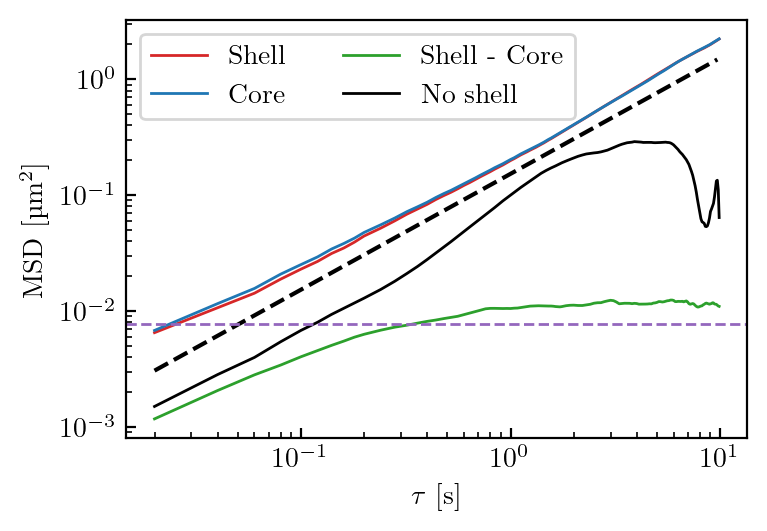

In [118]:
fig, ax = plt.subplots(1, 1, figsize=(10/2.54, 7/2.54))

ax.plot(dtimes, msdouter * 1e12, ls='-', lw=1, c='tab:red', label='Shell')
# ax.plot(dtimes, msdouter * 1e12, ls='', marker='o', c='tab:red', label='Shell')
ax.plot(dtimes, msdinner * 1e12, ls='-', lw=1, c='tab:blue', label='Core')
ax.plot(dtimes, msdboth * 1e12, ls='-', lw=1, c='tab:green', label='Shell - Core')

ax.plot(dtimes_noshell, msdnoshell * 1e12, ls='-', lw=1, c='k', label='No shell')
# ax.plot(dtimes_noshell, msdnoshell2 / (px**2), ls='-.', lw=1, c='k', label='No shell')

# ax.plot(dtimes[2:-2], 100 * dtimes[2:-2], ls='--', c='k')
ax.plot(dtimes[:-2], 2 * 0.36 * (4e-21) / (6*np.pi*0.001*1e-6) * dtimes[:-2] * 1e12, ls='--', c='k')

ax.axhline(y=(2*px)**2 * 1e12, ls='--', c='tab:purple', lw=1)

ax.legend(loc='upper left', ncol=2)
ax.set(xlabel=r'$\tau$ [s]', ylabel=r'MSD [\textmu$\mathrm{m^2}$]', xscale='log', yscale='log')

plt.tight_layout()
plt.show()

In [119]:
# fig.savefig()

In [120]:
plateau_MSD = np.nanmean(msdboth[(dtimes > 2) & (dtimes < 5)])
print(plateau_MSD)
print(np.sqrt(5/2 * plateau_MSD) * 1e9)

1.1654415045388417e-14
170.69281652568463


In [121]:
def pdf(data, bins=10, density=True, range=None):
    pdf, bins_edge = np.histogram(
        data, 
        bins=bins, 
        density=density, 
        range=range, 
    )
    bins_center = (bins_edge[0:-1] + bins_edge[1:]) / 2
    return pdf, bins_center

In [122]:
rr = np.sqrt((xinner[start:stop:step] - xouter[start:stop:step]) ** 2 + (yinner[start:stop:step] - youter[start:stop:step]) ** 2)

# rr = rr[:100]

In [123]:
Pr, bins_Pr = pdf(rr, bins=25, range=[0,300e-9])

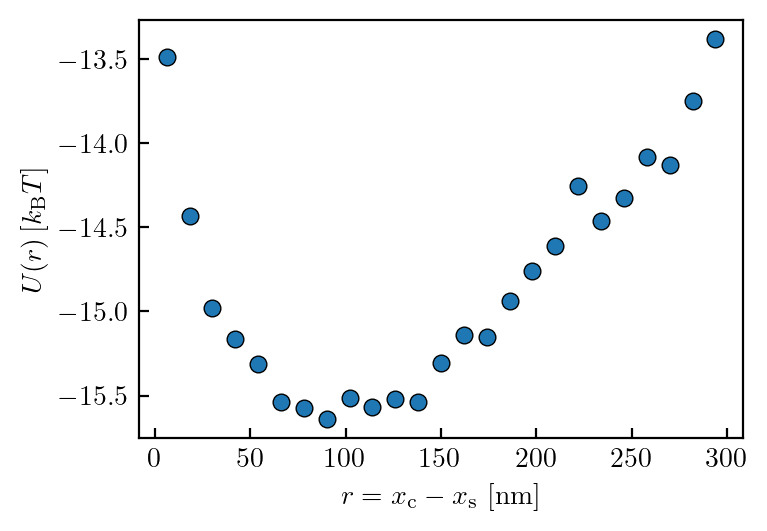

In [124]:
fig, ax = plt.subplots(1, 1, figsize=(10/2.54, 7/2.54))

ax.plot(bins_Pr*1e9, -np.log(Pr), ls='', marker='o')

ax.set(yscale='linear', xscale='linear', xlabel=r'$r = x_\mathrm{c} - x_\mathrm{s}$ [nm]', ylabel=r'$U(r) \, [k_\mathrm{B}T]$')

plt.tight_layout()
plt.show()

In [125]:
print(max(rr))

4.6967076977451124e-07


In [126]:
len(rr[np.isnan(rr)])

0

In [127]:
np.isfinite(np.log(Pr)[0])

np.True_

In [128]:
# ── Wiener-Khinchin (via autocorrelation) ──────────────────────────────
def autocorrelation_biased(a):
    a = a - np.mean(a)
    N = len(a)
    f = np.fft.rfft(a, n=2*N)
    acf = np.fft.irfft(f * np.conj(f))[:N]
    acf /= N  # divide by N instead of N-lag
    return acf
    
def compute_psd(a, dt):
    x_detrended = a #signal.detrend(a, type='linear')
    acf = autocorrelation_biased(x_detrended)
    psd_wk = np.fft.rfft(acf) * dt
    freqs_wk = np.fft.rfftfreq(len(acf), d=dt)
    return freqs_wk, psd_wk

In [129]:
freqs_outer, psd_xouter = compute_psd(xouter, dt=1/fps)
_, psd_youter = compute_psd(youter, dt=1/fps)

freqs_inner, psd_xinner = compute_psd(xinner, dt=1/fps)
_, psd_yinner = compute_psd(yinner, dt=1/fps)

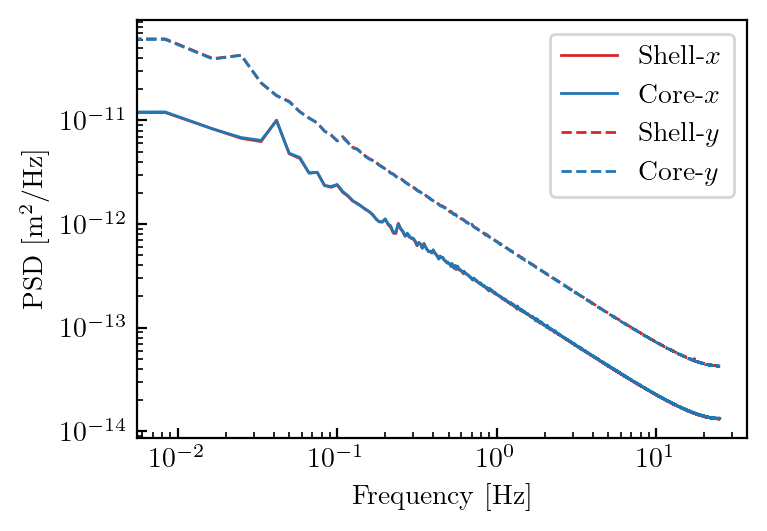

In [130]:
fig, ax = plt.subplots(1, 1, figsize=(10/2.54, 7/2.54))

ax.plot(freqs_outer, np.abs(psd_xouter), ls='-', lw=1, c='tab:red', label='Shell-$x$')
ax.plot(freqs_inner, np.abs(psd_xinner), ls='-', lw=1, c='tab:blue', label='Core-$x$')

ax.plot(freqs_outer, np.abs(psd_youter), ls='--', lw=1, c='tab:red', label='Shell-$y$')
ax.plot(freqs_inner, np.abs(psd_yinner), ls='--', lw=1, c='tab:blue', label='Core-$y$')

ax.legend()
ax.set(xlabel='Frequency [Hz]', ylabel=r'PSD [$\mathrm{m^2/Hz}$]', xscale='log', yscale='log')

# plt.ylim([1e-22, None])

plt.tight_layout()
plt.show()

In [131]:
def crosscorrelation_biased(a, b, dt):
    
    assert len(a) == len(b)
    
    a = a - np.mean(a)
    b = b - np.mean(b)
    N = len(a)

    fa = np.fft.rfft(a, n=2*N)
    fb = np.fft.rfft(b, n=2*N)

    # # cross-power spectrum: conj(fa) * fb gives corr(a,b) with b shifted forward
    # ccf = np.fft.irfft(np.conj(fa) * fb, n=2*N)
    # ccf /= N  # biased normalization, same convention as your acf

    # # reorder: irfft gives [lag 0, 1, ..., N-1, -(N), ..., -1]
    # # rearrange to [-(N-1), ..., -1, 0, 1, ..., N-1]
    # ccf = np.concatenate((ccf[-(N-1):], ccf[:N]))

    # lags = np.arange(-(N-1), N)
    # lags = lags * dt

    # cross-power spectrum: conj(fa) * fb gives corr(a,b) with b shifted forward
    ccf = np.fft.irfft(np.conj(fa) * fb, n=2*N)[:N]
    ccf /= N  # biased normalization, same convention as your acf

    lags = np.arange(0, N)
    lags = lags * dt
    
    return lags, ccf

In [132]:
lags_x, ccf_x = crosscorrelation_biased(xouter, xinner, dt=1/fps)
lags_y, ccf_y = crosscorrelation_biased(youter, yinner, dt=1/fps)

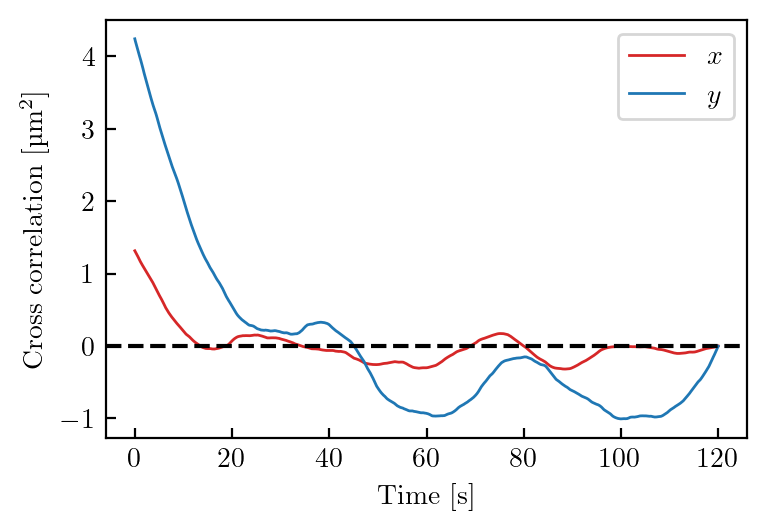

In [133]:
fig, ax = plt.subplots(1, 1, figsize=(10/2.54, 7/2.54))

ax.plot(lags_x, ccf_x * 1e12, ls='-', lw=1, c='tab:red', label='$x$')
ax.plot(lags_y, ccf_y * 1e12, ls='-', lw=1, c='tab:blue', label='$y$')

ax.axhline(y=0, ls='--', c='k')

ax.legend()
ax.set(xlabel='Time [s]', ylabel=r'Cross correlation [\textmu$\mathrm{m^2}$]', xscale='linear', yscale='linear')

plt.tight_layout()
plt.show()

In [134]:
path2save

'/home/nfares/postdoc/experiments/data/Rattler/20261002_rattler_diffusion_in_dextran/trajectories_testo008_fps_50Hz_calib_44nm_same_as_007_CROPPED_fps_50Hz_px_44nm'

In [135]:
test = pd.read_csv(path2save+'.csv')

In [136]:
test.head()

,frame,time,xs,ys,as,sigmas,Is_max,Is,xc,yc,Ac,Ic
0,0,0.00,0.000011,0.000009,0.000001,9.272361e-08,25789.672010,2.387678e+07,0.00001,0.000009,2.631024e-12,20285080.0
1,1,0.02,0.000010,0.000009,0.000001,9.272361e-08,26057.785534,2.412500e+07,0.00001,0.000009,2.561328e-12,19063339.0
2,2,0.04,0.000011,0.000009,0.000001,9.272361e-08,26279.413416,2.433019e+07,0.00001,0.000009,2.636832e-12,20884769.0
3,3,0.06,0.000011,0.000009,0.000001,9.272361e-08,26330.287675,2.437729e+07,0.00001,0.000009,2.590368e-12,19972623.0
4,4,0.08,0.000011,0.000009,0.000001,9.272361e-08,26418.309602,2.445879e+07,0.00001,0.000010,2.352240e-12,16985797.0


In [137]:
xouter = test["xs"].to_numpy()
youter = test["ys"].to_numpy()
Router = test["as"].to_numpy()
Souter = test["sigmas"].to_numpy()
xinner = test["xc"].to_numpy()
yinner = test["yc"].to_numpy()
time = test['time'].to_numpy()

In [138]:
from correlation_functions import *

In [139]:
# dframes = np.arange(2, 500, 1)

In [140]:
ccf_x = correlation(xouter, xinner, dframes)
ccf_y = correlation(youter, yinner, dframes)

lags_x = dframes / fps
lags_y = dframes / fps

In [141]:
print(len(ccf_x))

134


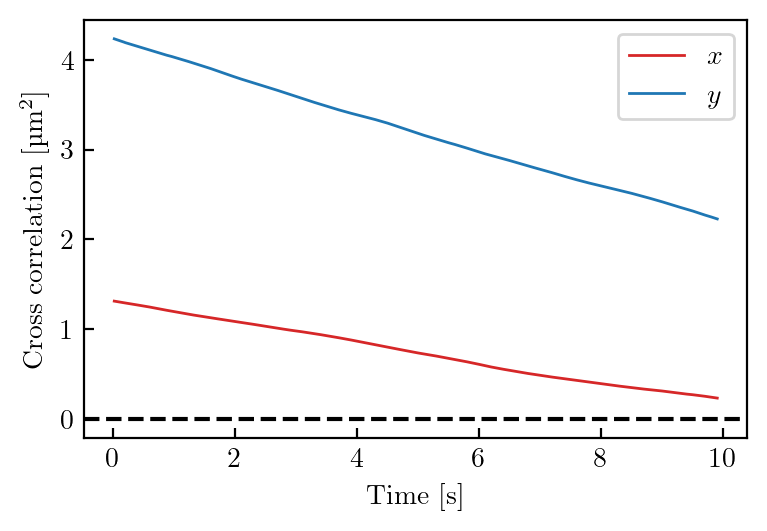

In [142]:
fig, ax = plt.subplots(1, 1, figsize=(10/2.54, 7/2.54))

ax.plot(lags_x, ccf_x * 1e12, ls='-', lw=1, c='tab:red', label='$x$')
ax.plot(lags_y, ccf_y * 1e12, ls='-', lw=1, c='tab:blue', label='$y$')

ax.axhline(y=0, ls='--', c='k')

ax.legend()
ax.set(xlabel='Time [s]', ylabel=r'Cross correlation [\textmu$\mathrm{m^2}$]', xscale='linear', yscale='linear')

plt.tight_layout()
plt.show()

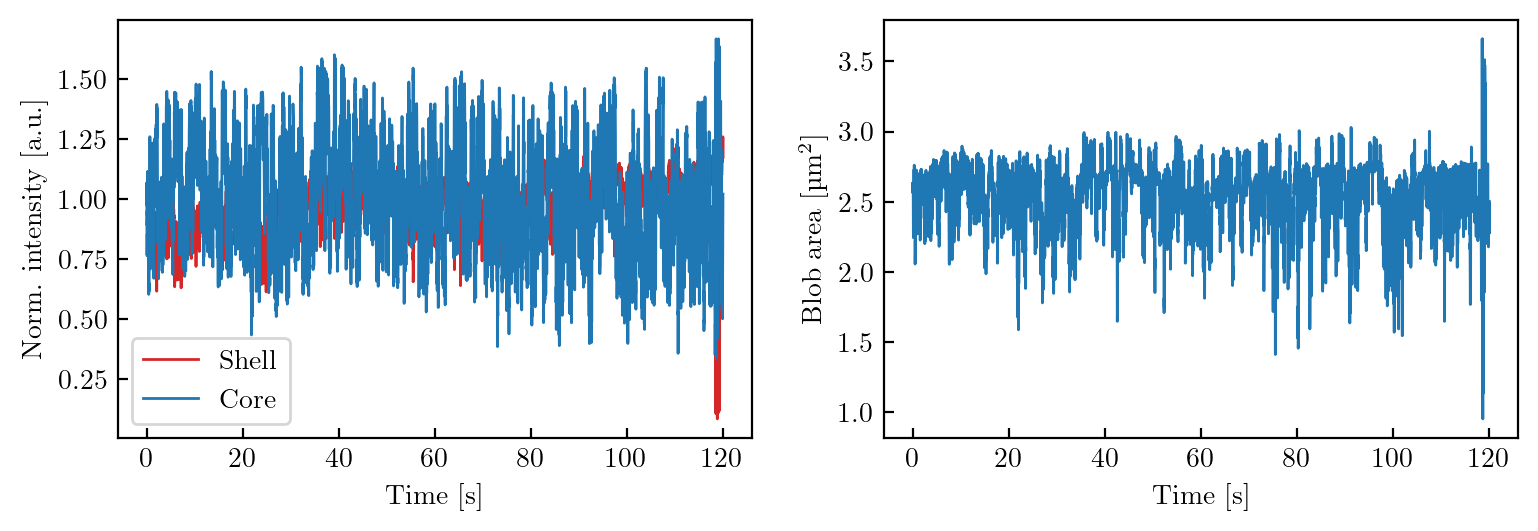

In [143]:
fig, axes = plt.subplots(1, 2, figsize=(20/2.54, 7/2.54))

axes[0].plot(time, iouter / np.nanmean(iouter), ls='-', lw=1, c='tab:red', label='Shell')
axes[0].plot(time, iinner / np.nanmean(iinner), ls='-', lw=1, c='tab:blue', label='Core')

axes[1].plot(time, ainner * 1e12, ls='-', lw=1, c='tab:blue', label='Shell')

axes[0].legend()
axes[0].set(xlabel='Time [s]', ylabel=r'Norm. intensity [a.u.]', xscale='linear', yscale='linear')

axes[1].set(xlabel='Time [s]', ylabel=r'Blob area [\textmu m$^2$]', xscale='linear', yscale='linear')

plt.tight_layout()
plt.show()

In [144]:
# dframes = np.concatenate((np.arange(1, 10, 1), np.arange(10, 100, 2), np.arange(100, 500, 5)))

msdiinner = moment(2, iinner, dframes, retrieve_mean=False)
msdainner = moment(2, ainner, dframes, retrieve_mean=False)

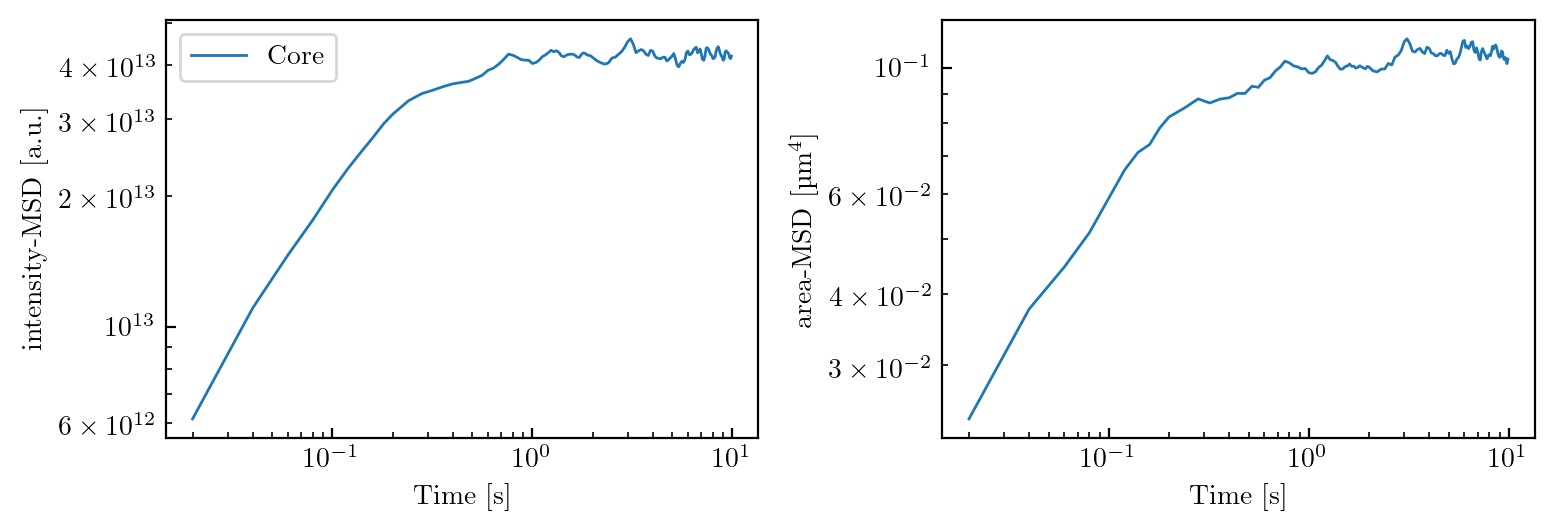

In [145]:
fig, axes = plt.subplots(1, 2, figsize=(20/2.54, 7/2.54))

axes[0].plot(dtimes, msdiinner, ls='-', lw=1, c='tab:blue', label='Core')

axes[1].plot(dtimes, msdainner * 1e24, ls='-', lw=1, c='tab:blue', label='Core')

axes[0].legend()
axes[0].set(xlabel='Time [s]', ylabel=r'intensity-MSD [a.u.]', xscale='log', yscale='log')

axes[1].set(xlabel='Time [s]', ylabel=r'area-MSD [\textmu m$^4$]', xscale='log', yscale='log')

plt.tight_layout()
plt.show()